# Прогноз схвалення займу: аналіз даних

Мета ноутбука - зрозуміти, з якими даними працюємо, перш ніж будувати модель:
що в кожній колонці, де пропуски, як розподілена цільова змінна і які ознаки на неї впливають.

In [1]:
import joblib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

df = pd.read_csv("loan_data.csv")
print(df.shape)
df.head()

(381, 13)


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
1,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
2,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
3,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
4,LP001013,Male,Yes,0,Not Graduate,No,2333,1516.0,95.0,360.0,1.0,Urban,Y


## Типи колонок

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 381 entries, 0 to 380
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            381 non-null    str    
 1   Gender             376 non-null    str    
 2   Married            381 non-null    str    
 3   Dependents         373 non-null    str    
 4   Education          381 non-null    str    
 5   Self_Employed      360 non-null    str    
 6   ApplicantIncome    381 non-null    int64  
 7   CoapplicantIncome  381 non-null    float64
 8   LoanAmount         381 non-null    float64
 9   Loan_Amount_Term   370 non-null    float64
 10  Credit_History     351 non-null    float64
 11  Property_Area      381 non-null    str    
 12  Loan_Status        381 non-null    str    
dtypes: float64(4), int64(1), str(8)
memory usage: 38.8 KB


## Пропущені значення

Рахую і кількість, і частку: 30 пропусків у колонці з 381 рядка - це майже 8%,
таку колонку не можна просто викинути разом із рядками.

In [3]:
missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
pd.DataFrame({"кількість": missing, "частка, %": (missing / len(df) * 100).round(1)})

,кількість,"частка, %"
Credit_History,30,7.9
Self_Employed,21,5.5
Loan_Amount_Term,11,2.9
Dependents,8,2.1
Gender,5,1.3


## Цільова змінна `Loan_Status`

In [4]:
pd.DataFrame({
    "кількість": df["Loan_Status"].value_counts(),
    "частка, %": (df["Loan_Status"].value_counts(normalize=True) * 100).round(1),
})

,кількість,"частка, %"
Loan_Status,,
Y,271,71.1
N,110,28.9


## Числові колонки

In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
ApplicantIncome,381.0,3579.845144,1419.813818,150.0,2600.0,3333.0,4288.0,9703.0
CoapplicantIncome,381.0,1277.275381,2340.818114,0.0,0.0,983.0,2016.0,33837.0
LoanAmount,381.0,104.986877,28.358464,9.0,90.0,110.0,127.0,150.0
Loan_Amount_Term,370.0,340.864865,68.549257,12.0,360.0,360.0,360.0,480.0
Credit_History,351.0,0.837607,0.369338,0.0,1.0,1.0,1.0,1.0


## Розподіл числових ознак за результатом

Накладаю гістограми схвалених і відхилених заявок: якщо ознака впливає на рішення,
їхні форми помітно розходяться. Діапазон кожного графіка обмежую 99-м перцентилем: у `CoapplicantIncome`
є викид 33837, через який решта даних стиснулася б у кілька стовпчиків.

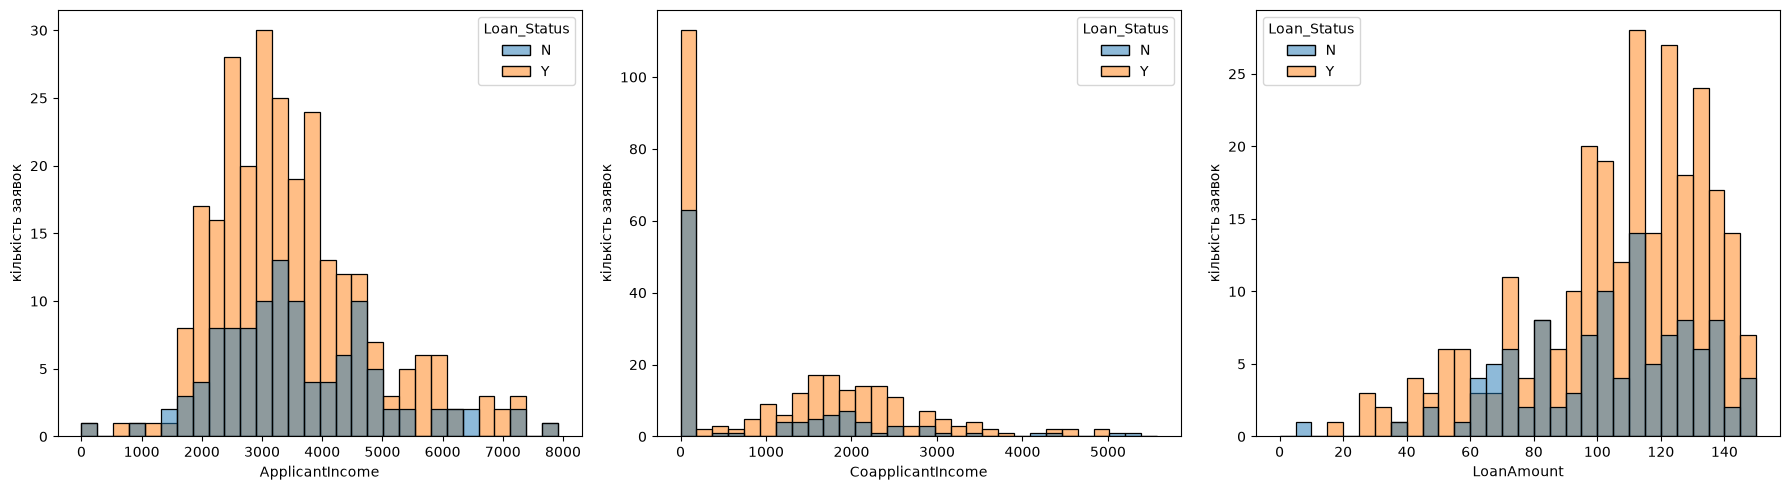

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, column in zip(axes, ["ApplicantIncome", "CoapplicantIncome", "LoanAmount"]):
    upper = df[column].quantile(0.99)
    sns.histplot(data=df, x=column, hue="Loan_Status", bins=30, binrange=(0, upper), ax=ax)
    ax.set_ylabel("кількість заявок")

plt.tight_layout()
plt.show()

## Категоріальні колонки

`Credit_History` і `Loan_Amount_Term` записані числами, але за змістом це категорії:
кредитна історія має лише значення 0 і 1, а строк займу - фіксований набір варіантів.

In [7]:
categorical = ["Gender", "Married", "Dependents", "Education", "Self_Employed",
               "Property_Area", "Credit_History", "Loan_Amount_Term"]

for column in categorical:
    print(df[column].value_counts(dropna=False), end="\n\n")

Gender
Male      291
Female     85
NaN         5
Name: count, dtype: int64

Married
Yes    228
No     153
Name: count, dtype: int64

Dependents
0      234
2       59
1       52
3+      28
NaN      8
Name: count, dtype: int64

Education
Graduate        278
Not Graduate    103
Name: count, dtype: int64

Self_Employed
No     325
Yes     35
NaN     21
Name: count, dtype: int64

Property_Area
Semiurban    149
Urban        126
Rural        106
Name: count, dtype: int64

Credit_History
1.0    294
0.0     57
NaN     30
Name: count, dtype: int64

Loan_Amount_Term
360.0    312
180.0     29
NaN       11
480.0     11
300.0      7
120.0      3
84.0       3
240.0      2
60.0       1
12.0       1
36.0       1
Name: count, dtype: int64



## Кореляція числових ознак із результатом

Щоб порахувати кореляцію, перетворюю `Loan_Status` на число: 1 - схвалено, 0 - ні.
Шкала кольорів симетрична від -1 до 1, нуль - нейтральний колір,
тож сильний зв'язок в обидва боки видно одразу.

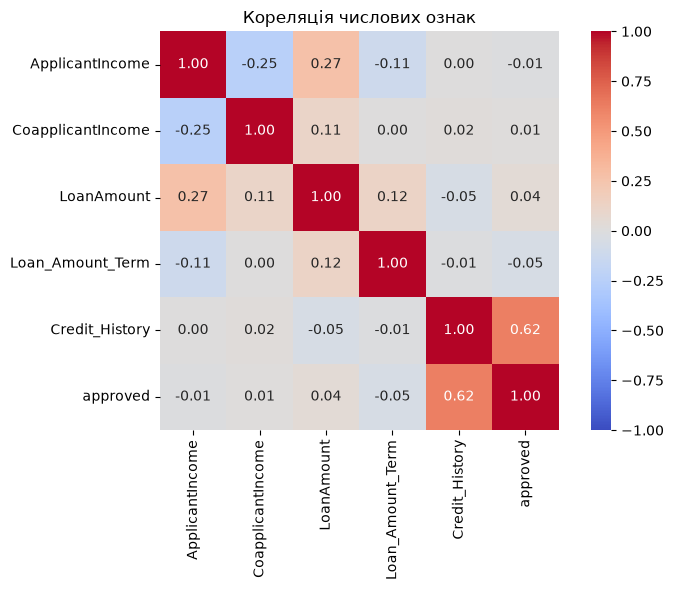

In [8]:
df["approved"] = (df["Loan_Status"] == "Y").astype(int)

numeric = ["ApplicantIncome", "CoapplicantIncome", "LoanAmount",
           "Loan_Amount_Term", "Credit_History", "approved"]

plt.figure(figsize=(8, 6))
sns.heatmap(df[numeric].corr(), annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, center=0, square=True)
plt.title("Кореляція числових ознак")
plt.tight_layout()
plt.show()

## Частка схвалених заявок у кожній категорії

Кореляція Пірсона не підходить для текстових категорій, тому для них дивлюся,
яка частка заявок схвалена в кожній групі. Пунктир - середня частка по всій вибірці.
Під кожним стовпчиком указано кількість заявок: висновок по групі з 1-3 заявок ненадійний.

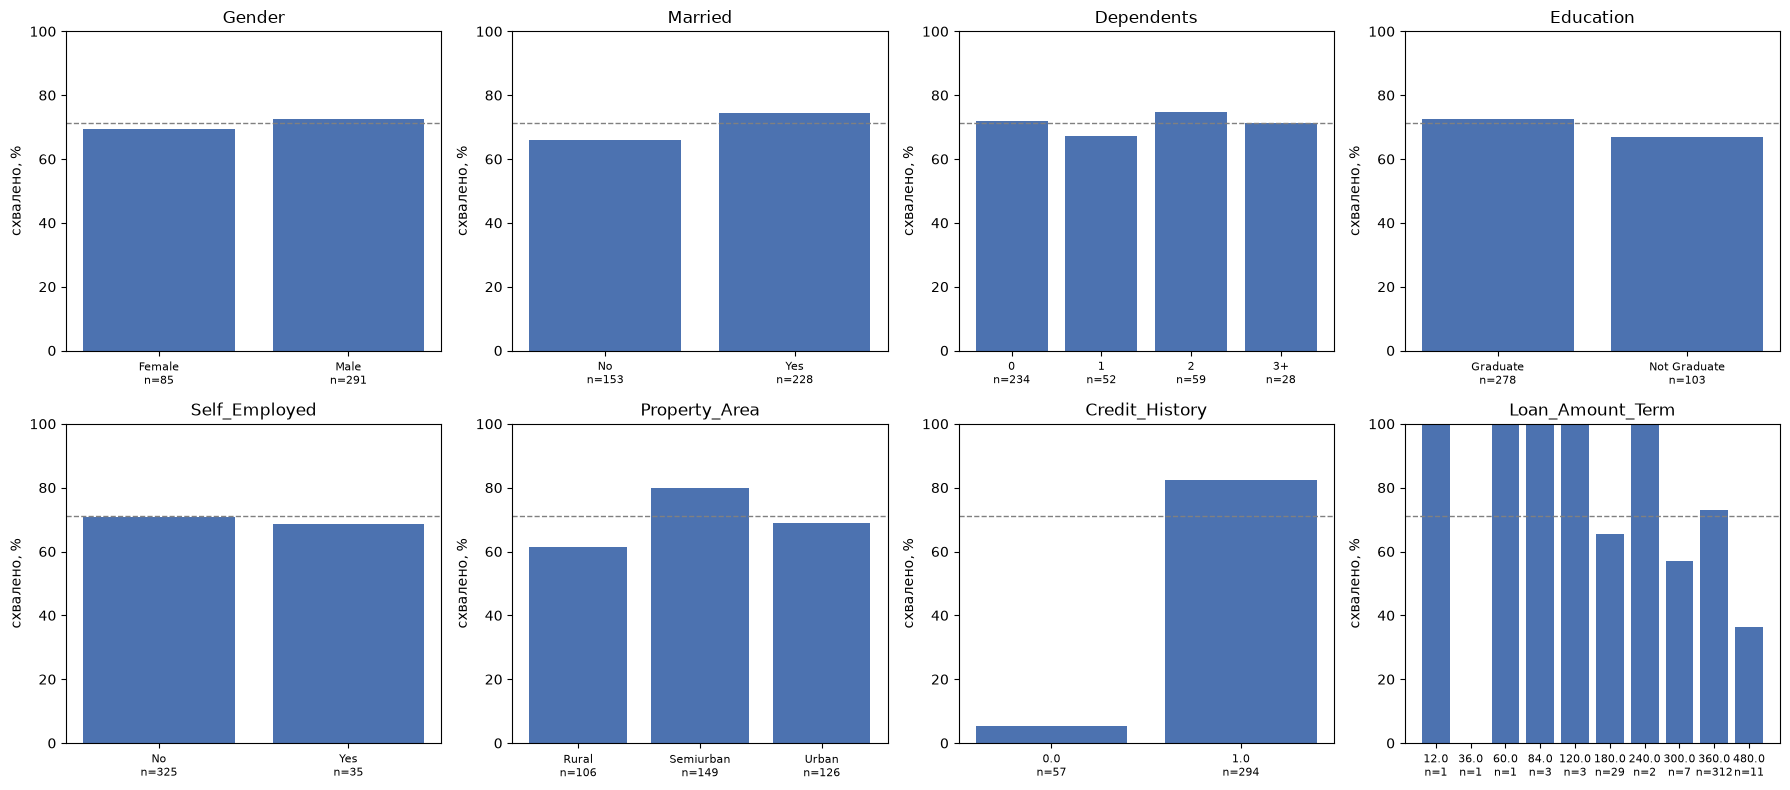

In [9]:
overall_rate = df["approved"].mean() * 100

fig, axes = plt.subplots(2, 4, figsize=(18, 8))

for ax, column in zip(axes.flat, categorical):
    stats = df.groupby(column)["approved"].agg(["mean", "count"])
    labels = [f"{value}\nn={count}" for value, count in stats["count"].items()]
    ax.bar(labels, stats["mean"] * 100, color="#4C72B0")
    ax.axhline(overall_rate, color="gray", linestyle="--", linewidth=1)
    ax.set_title(column)
    ax.set_ylim(0, 100)
    ax.set_ylabel("схвалено, %")
    ax.tick_params(axis="x", labelsize=8)

plt.tight_layout()
plt.show()

## Важливість ознак у навченій моделі

Модель навчає скрипт `train_model.py` і зберігає у `ml/loan_model.joblib`.
Після OneHotEncoder кожне значення категорії стає окремою ознакою,
тому в списку є, наприклад, і `Credit_History_0.0`, і `Credit_History_1.0`.

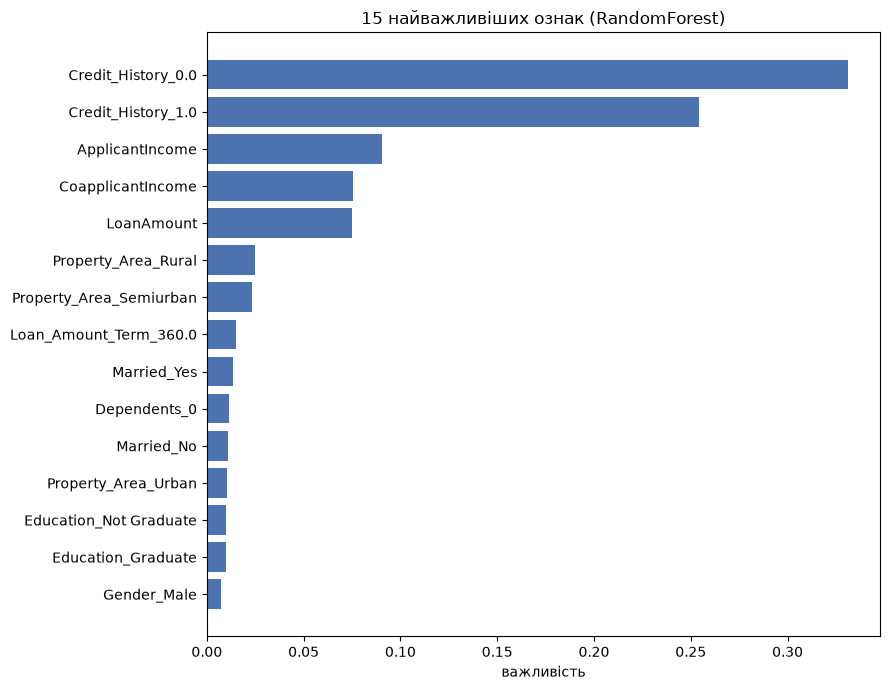

In [10]:
model = joblib.load("ml/loan_model.joblib")

feature_names = model.named_steps["preprocessor"].get_feature_names_out()
feature_names = [name.split("__", 1)[1] for name in feature_names]
importances = pd.Series(model.named_steps["classifier"].feature_importances_, index=feature_names)
top = importances.sort_values().tail(15)

plt.figure(figsize=(9, 7))
plt.barh(top.index, top.values, color="#4C72B0")
plt.title("15 найважливіших ознак (RandomForest)")
plt.xlabel("важливість")
plt.tight_layout()
plt.show()

## Висновки з аналізу

- **Кредитна історія - головний чинник.** Кореляція `Credit_History` із результатом 0.62.
  З кредитною історією схвалено 82.3% заявок, без неї - лише 5.3% (3 з 57).
- **Доходи й сума займу майже не пов'язані з рішенням напряму:**
  кореляція з результатом від -0.05 до 0.04.
- **Серед категорій помітні відмінності дає район нерухомості:**
  Semiurban - 79.9% схвалень, Rural - 61.3%, Urban - 69.0%.
  Одружені отримують схвалення частіше (74.6%), ніж неодружені (66.0%).
- **Стать, освіта, самозайнятість і кількість утриманців** змінюють частку схвалень
  лише на кілька відсоткових пунктів.
- **За строком займу** більшість заявок (312 з 370) мають строк 360 місяців.
  Решта груп малі, і 0% або 100% у групі з однієї-трьох заявок - випадковість, а не закономірність.
- **Модель підтверджує аналіз:** дві ознаки кредитної історії разом дають 0.58 загальної важливості.
  Доходи й сума займу йдуть наступними (0.07-0.09 кожна): лінійної кореляції з результатом
  в них майже немає, але дерева знаходять у них корисні пороги.